# PyGeoParallax-IN quick start

This notebook corrects one INSAT-3DR Imager L1C file for cloud parallax, step by step:

1. read a region of the file;
2. derive cloud-top height from the 10.8 µm channel;
3. correct onto a regular lat/lon grid, and onto the file's own pixel grid;
4. use a lower, *effective* height for precipitation work;
5. do the same from the command line.

**You need**

- the package with plotting: `pip install -e ".[plot]"` from the repository;
- one L1C sector file, `3RIMG_<date>_<time>_L1C_SGP_V01R00.h5`, from [MOSDAC](https://www.mosdac.gov.in). Set its path in the next cell, or in the environment variable `PYGEOPARALLAX_L1C`.

The example uses 1 August 2023, 18:15 UTC, with monsoon convection over central India and the Bay of Bengal.

In [1]:
import os

import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
import numpy as np

import pygeoparallax
from pygeoparallax.cloudheight import cloud_top_height, effective_height
from pygeoparallax.geometry import SATELLITE_LONGITUDES, satellite_view_angles
from pygeoparallax.ingest import read_insat_l1c
from pygeoparallax.pipeline import correct_native, correct_scene
from pygeoparallax.resample import Grid

L1C = os.environ.get("PYGEOPARALLAX_L1C", "3RIMG_01AUG2023_1815_L1C_SGP_V01R00.h5")
print("pygeoparallax", pygeoparallax.__version__)

pygeoparallax 0.3.0


## 1. Read a region

`read_insat_l1c` decodes the 10-bit counts to brightness temperature [K] and computes each pixel's latitude and longitude from the file's Mercator grid. `bbox` reads only part of the sector, which is much faster.

In [2]:
BBOX = (18.0, 26.0, 80.0, 90.0)          # lat_min, lat_max, lon_min, lon_max
scene = read_insat_l1c(L1C, channels=("TIR1", "TIR2", "WV", "MIR"), bbox=BBOX)
lat, lon = scene["lat"].values, scene["lon"].values
bt = scene["TIR1"].values
sat_lon = scene.attrs["sub_satellite_longitude"]
print(scene.attrs["satellite"], scene.attrs["time"], "sub-satellite longitude", sat_lon)
print(dict(scene.sizes), f"TIR1 {np.nanmin(bt):.0f}-{np.nanmax(bt):.0f} K")

INSAT-3DR 2023-08-01T18:28:53 sub-satellite longitude 74.0
{'y': 239, 'x': 278} TIR1 180-290 K


## 2. Cloud-top height

Where TIR1 is colder than 270 K the pixel is taken as cloud, and its height is where the AFGL tropical atmosphere has that temperature. Clear pixels get NaN (they are not moved). Tops colder than the tropopause are capped at it (17 km).

The parallax is roughly height × tan(viewing zenith angle). INSAT-3DR sits at 74°E, so over India it looks north and slightly east or west, and the angle grows with latitude.

cloudy 97%, median cloud-top height 14.0 km
viewing zenith angle 22-35 deg; a 15 km top is displaced by about 6-11 km


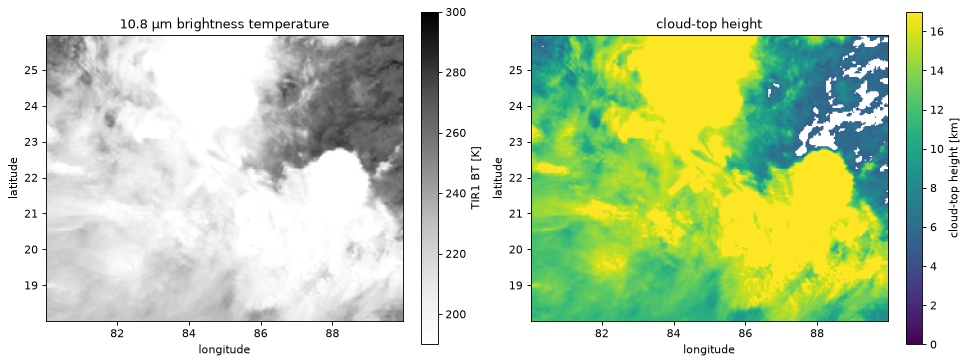

In [3]:
cth = cloud_top_height(bt)
vza, _ = satellite_view_angles(lat, lon, sat_lon)
print(f"cloudy {np.isfinite(cth).mean():.0%}, median cloud-top height {np.nanmedian(cth) / 1000:.1f} km")
print(f"viewing zenith angle {vza.min():.0f}-{vza.max():.0f} deg; "
      f"a 15 km top is displaced by about {15 * np.tan(np.radians(vza.min())):.0f}-{15 * np.tan(np.radians(vza.max())):.0f} km")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
ext = (lon.min(), lon.max(), lat.min(), lat.max())
im = ax[0].imshow(bt, extent=ext, cmap="Greys", vmin=190, vmax=300)
fig.colorbar(im, ax=ax[0], label="TIR1 BT [K]")
im = ax[1].imshow(cth / 1000, extent=ext, cmap="viridis", vmin=0, vmax=17)
fig.colorbar(im, ax=ax[1], label="cloud-top height [km]")
for a, t in zip(ax, ("10.8 µm brightness temperature", "cloud-top height")):
    a.set_title(t); a.set_xlabel("longitude"); a.set_ylabel("latitude")

## 3a. Correct onto a regular lat/lon grid

`correct_scene` moves every cloudy pixel to where its cloud top really is (ellipsoid ray tracing) and puts the result on a `Grid`. Where several pixels land in one cell the highest wins, because it hides the others from the satellite. Small gaps are interpolated, and the cells behind tall clouds that the satellite never saw stay empty.

`correct=False` gives the uncorrected scene on exactly the same grid, for comparison.

In [4]:
grid = Grid(lat_min=18.5, lat_max=25.5, lon_min=80.5, lon_max=89.5, res=0.04)
channels = {c: scene[c].values for c in ("TIR1", "TIR2", "WV", "MIR")}
cor = correct_scene(lat, lon, channels, cth, sat_lon=sat_lon, grid=grid)
raw = correct_scene(lat, lon, channels, cth, sat_lon=sat_lon, grid=grid, correct=False)

cloudy = np.isfinite(cor["cth"].values)
s = cor["shift_km"].values[cloudy]
print(f"shift of cloudy pixels: median {np.median(s):.1f} km, 95th percentile {np.percentile(s, 95):.1f} km")
print("fill_flag (0 observed, 1 interpolated, 2 empty):",
      {k: f"{(cor['fill_flag'].values == k).mean():.2%}" for k in (0, 1, 2)})

shift of cloudy pixels: median 7.6 km, 95th percentile 10.2 km
fill_flag (0 observed, 1 interpolated, 2 empty): {0: '99.57%', 1: '0.43%', 2: '0.00%'}


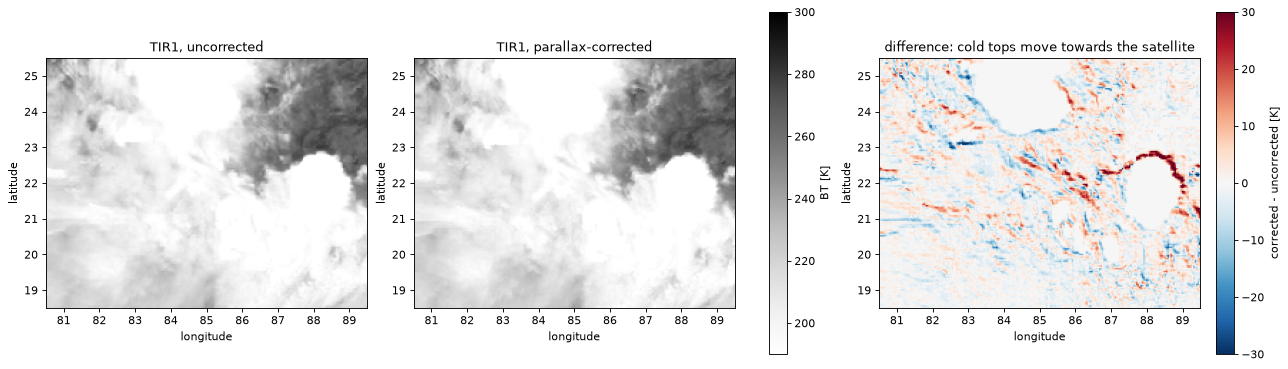

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
ext = (grid.lon_min, grid.lon_max, grid.lat_min, grid.lat_max)
for a, ds, t in ((ax[0], raw, "uncorrected"), (ax[1], cor, "parallax-corrected")):
    im = a.imshow(ds["TIR1"], extent=ext, cmap="Greys", vmin=190, vmax=300)
    a.set_title(f"TIR1, {t}")
fig.colorbar(im, ax=ax[:2], label="BT [K]")
im = ax[2].imshow(cor["TIR1"] - raw["TIR1"], extent=ext, cmap="RdBu_r", vmin=-30, vmax=30)
fig.colorbar(im, ax=ax[2], label="corrected - uncorrected [K]")
ax[2].set_title("difference: cold tops move towards the satellite")
for a in ax:
    a.set_xlabel("longitude"); a.set_ylabel("latitude")

## 3b. Correct on the file's own pixel grid

`correct_native` does the same correction but puts the result back on the input pixels: same shape, same pixel centres. Use it when the corrected and uncorrected images must line up pixel for pixel, for example as inputs to a model trained on L1C tiles. `fill_empty=True` fills the few cells no pixel reached with the nearest corrected value (they keep `fill_flag` 2), so the image has no holes.

(239, 278) same as input: True
TIR1 changed by more than 1 K on 65% of pixels


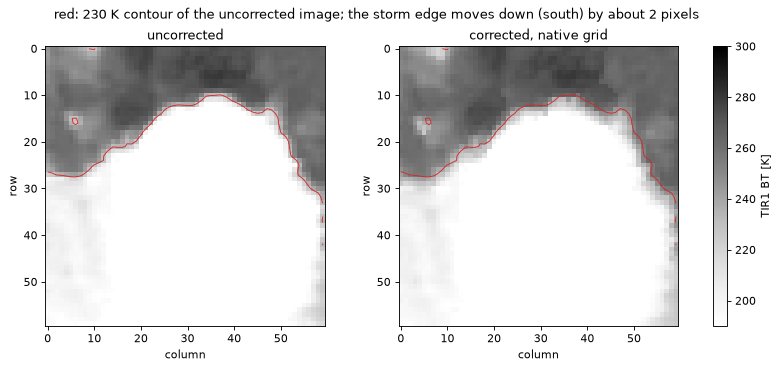

In [6]:
nat = correct_native(lat, lon, channels, cth, sat_lon=sat_lon, fill_empty=True)
print(nat["TIR1"].shape, "same as input:", nat["TIR1"].shape == bt.shape)
print(f"TIR1 changed by more than 1 K on {(np.abs(nat['TIR1'].values - bt) > 1).mean():.0%} of pixels")

r0, c0 = np.unravel_index(np.argmin(np.hypot(lat - 22.2, lon - 88.0)), bt.shape)  # zoom on a storm edge
win = (slice(r0 - 30, r0 + 30), slice(c0 - 30, c0 + 30))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
for a, img, t in ((ax[0], bt, "uncorrected"), (ax[1], nat["TIR1"].values, "corrected, native grid")):
    im = a.imshow(img[win], cmap="Greys", vmin=190, vmax=300)
    a.contour(bt[win], levels=[230], colors="tab:red", linewidths=0.8)
    a.set_title(t); a.set_xlabel("column"); a.set_ylabel("row")
fig.colorbar(im, ax=ax, label="TIR1 BT [K]")
fig.suptitle("red: 230 K contour of the uncorrected image; the storm edge moves down (south) by about 2 pixels");

## 4. Effective height for precipitation

The infrared height is the top of the cloud, which is right for cloud products. Rain sits lower: in our validation against GPM DPR, the coldest convective tops were a median 3.2 km above the radar storm top. For precipitation work you can correct with a lower, effective height. `effective_height(cth, scale, offset)` returns `scale × cth − offset`, floored at 0 m.

In [7]:
for offset in (0, 3000):
    ds = correct_scene(lat, lon, {"TIR1": bt}, effective_height(cth, offset=offset), sat_lon=sat_lon, grid=grid)
    c = np.isfinite(ds["cth"].values)
    print(f"offset {offset / 1000:.0f} km: median shift {np.median(ds['shift_km'].values[c]):.1f} km")

offset 0 km: median shift 7.6 km
offset 3 km: median shift 6.0 km


## 5. Command line

The `l1c` command does all of the above for whole files, in parallel. It writes one NetCDF per input.

```bash
# regular 0.04 deg grid over South Asia (0-40N, 60-100E)
pygeoparallax l1c "L1C/3RIMG_*_L1C_SGP_V01R00.h5" -o corrected/

# the file's own pixel grid, gaps filled, a region only
pygeoparallax l1c "L1C/*.h5" -o corrected_native/ --native --fill-empty --bbox 5 30 68 98

# uncorrected baseline on the same grid
pygeoparallax l1c "L1C/*.h5" -o uncorrected/ --no-correction

# effective height for precipitation, ERA5 profiles, terrain, navigation correction
pygeoparallax l1c "L1C/*.h5" -o corrected/ --height-offset 3 --era5 era5_pl.nc --dem srtm.nc --nav-correction nav.json
```

`pygeoparallax l1c --help` lists every option. `pygeoparallax navigation` measures a navigation correction from coastlines (see the README).